In [24]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import statsmodels.formula.api as smf
from itertools import product
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay,average_precision_score
)
from itertools import combinations
from scipy import sparse
from threadpoolctl import threadpool_limits

SEED = 42
SAMPLE_FRACTION = 1  # 0.05%
DATA_PATH = "datasets/USDOT_1987_2025_Flights_Dataset/flights_2008_2025_cleaned.parquet"

In [2]:
parquet = pq.ParquetFile(DATA_PATH)
sample_size = round(parquet.metadata.num_rows * SAMPLE_FRACTION)
rng = np.random.default_rng(SEED)
positions = np.sort(rng.choice(parquet.metadata.num_rows, sample_size, replace=False))

parts = []
offset = 0
for group in range(parquet.num_row_groups):
    end = offset + parquet.metadata.row_group(group).num_rows
    rows = positions[(positions >= offset) & (positions < end)] - offset
    if len(rows):
        table = parquet.read_row_group(group)
        parts.append(table.take(rows).to_pandas())
    offset = end
data = pd.concat(parts, ignore_index=True)
print(f"Sample: {len(data):,} flights")

Sample: 114,362,496 flights


In [4]:
airport_df = pd.read_csv('datasets/USDOT_1987_2025_Flights_Dataset/airports.csv')
airport_df = airport_df[['airport_id', 'airport_code']]

airport_dict = (
    airport_df
    .set_index("airport_id")["airport_code"]
    .to_dict()
)
data['origin_airport'] = data['origin_airport_id'].map(airport_dict)
data['dest_airport'] = data['dest_airport_id'].map(airport_dict)
data.drop('dest_airport_id', axis=1, inplace=True)
data.drop('origin_airport_id', axis=1, inplace=True)



In [9]:
def hhmm_to_minutes(series):
    # Convert values to strings and remove colons
    times = (
        series.astype("string")
        .str.strip()
        .str.replace(":", "", regex=False)
    )

    # Convert HHMM strings into numbers
    times = pd.to_numeric(times, errors="coerce")

    # Extract hours and minutes
    hours = times // 100
    minutes = times % 100

    # Check for valid time values
    valid = (
        hours.between(0, 23)
        & minutes.between(0, 59)
    )

    # Convert to minutes since midnight
    total_minutes = hours * 60 + minutes

    return total_minutes.where(valid)

data['scheduled_arrival_minutes'] = hhmm_to_minutes(data['scheduled_arrival_hhmm'])
data['crs_dep_time_minutes'] = hhmm_to_minutes(data['crs_dep_time_hhmm'])
data.drop('crs_dep_time_hhmm', axis=1, inplace=True)
data.drop('scheduled_arrival_hhmm', axis=1, inplace=True)

In [7]:
top_20_dest = (
    data["dest_airport"]
    .value_counts()
    .head(20)
    .index
)


data["dest_airport_group"] = np.where(
    data["dest_airport"].isin(top_20_dest),
    data["dest_airport"],
    "Other"
)

In [10]:

flights_ord = data.loc[
    (data["origin_airport"] == "ORD") &
    (data["cancelled"] == 0) &
    (data["diverted"] == 0) &
    data["arrival_delay"].notna()
].copy()

# Scheduled departure date and time in Chicago local time
flight_dates = pd.to_datetime(
    flights_ord["formatted_date"],
    errors="coerce"
).dt.normalize()

flights_ord["scheduled_departure_local"] = (
    flight_dates +
    pd.to_timedelta(
        flights_ord["crs_dep_time_minutes"],
        unit="m"
    )
)

# Chicago observes daylight saving time
local_times = flights_ord["scheduled_departure_local"].dt.tz_localize(
    "America/Chicago",
    ambiguous="NaT",
    nonexistent="NaT"
)

flights_ord["scheduled_departure_utc"] = (
    local_times.dt.tz_convert("UTC")
)

# Remove unresolved departure timestamps
flights_ord = flights_ord.dropna(
    subset=["scheduled_departure_utc"]
).copy()

# One-hour prediction cutoff
flights_ord["prediction_time_utc"] = (
    flights_ord["scheduled_departure_utc"] -
    pd.Timedelta(hours=1)
)

# Binary target
flights_ord["is_delayed"] = (
    flights_ord["arrival_delay"] >= 15
).astype(int)

print("ORD departures:", len(flights_ord))

print(
    flights_ord[
        ["scheduled_departure_utc", "prediction_time_utc"]
    ].head()
)


ORD departures: 5096750
        scheduled_departure_utc       prediction_time_utc
22619 2008-07-02 00:15:00+00:00 2008-07-01 23:15:00+00:00
22620 2008-07-03 00:15:00+00:00 2008-07-02 23:15:00+00:00
22621 2008-07-04 00:15:00+00:00 2008-07-03 23:15:00+00:00
22622 2008-07-05 00:15:00+00:00 2008-07-04 23:15:00+00:00
22623 2008-07-06 00:15:00+00:00 2008-07-05 23:15:00+00:00


In [11]:
data.to_parquet('ORD_FLIGHT_WEATHER.parquet')

In [12]:

DATA_PATH = "datasets/NOAA_Weather/weather_cleaned.parquet"
parquet = pq.ParquetFile(DATA_PATH)
sample_size = round(parquet.metadata.num_rows * SAMPLE_FRACTION)
rng = np.random.default_rng(SEED)
positions = np.sort(rng.choice(parquet.metadata.num_rows, sample_size, replace=False))

parts = []
offset = 0
for group in range(parquet.num_row_groups):
    end = offset + parquet.metadata.row_group(group).num_rows
    rows = positions[(positions >= offset) & (positions < end)] - offset
    if len(rows):
        table = parquet.read_row_group(group)
        parts.append(table.take(rows).to_pandas())
    offset = end
sample = pd.concat(parts, ignore_index=True)
print(f"Sample: {len(sample):,} flights")

weather_ord = sample.loc[sample['airport_code']=='ORD'].copy()
data.to_parquet('weather_ord.parquet')

Sample: 5,828,408 flights


In [13]:
weather_features = [
    "temperature_c",
    "dew_point_depression",
    "visibility_km",
    "precipitation_mm",
    "wind_speed_m_s",
    "wind_gust_m_s",
    "ceiling_height_m"
]

weather_columns = [
    "temperature_c",
    "dew_point_c",
    "visibility_km",
    "precipitation_mm",
    "wind_speed_m_s",
    "wind_gust_m_s",
    "ceiling_height_m"
]

weather = weather_ord.copy()

weather["timestamp_utc"] = pd.to_datetime(
    weather["timestamp_utc"],
    utc=True,
    errors="coerce"
)

weather = weather[
    ["timestamp_utc"] + weather_columns
].copy()

for col in weather_columns:
    weather[col] = pd.to_numeric(
        weather[col],
        errors="coerce"
    )

# Dew-point depression
weather["dew_point_depression"] = (
    weather["temperature_c"] -
    weather["dew_point_c"]
)

# Sort weather observations chronologically
weather = (
    weather
    .dropna(subset=["timestamp_utc"])
    .sort_values("timestamp_utc")
)

# This example assumes one station-level row per timestamp
weather = weather.drop_duplicates(
    subset="timestamp_utc",
    keep="last"
)


In [14]:
# Sort both datasets for chronological matching
flights_ord = flights_ord.sort_values(
    "prediction_time_utc"
)

weather = weather.sort_values("timestamp_utc")

# Backward as-of merge
ord_combined = pd.merge_asof(
    flights_ord,
    weather[
        ["timestamp_utc"] + weather_features
    ],
    left_on="prediction_time_utc",
    right_on="timestamp_utc",
    direction="backward",
    tolerance=pd.Timedelta("2h")
)

# Calculate weather observation age
ord_combined["weather_age_minutes"] = (
    (
        ord_combined["prediction_time_utc"] -
        ord_combined["timestamp_utc"]
    )
    .dt.total_seconds() / 60
)

# Verify matching quality
print("Flights:", len(ord_combined))

print(
    "Weather match rate:",
    f"{ord_combined['timestamp_utc'].notna().mean():.2%}"
)

print("\nWeather observation age:")
print(ord_combined["weather_age_minutes"].describe())

print("\nMissing weather measurements:")
display(
    ord_combined[weather_features]
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)


Flights: 5096750
Weather match rate: 99.93%

Weather observation age:
count    5.093198e+06
mean     2.531444e+01
std      1.756682e+01
min      0.000000e+00
25%      9.000000e+00
50%      2.400000e+01
75%      3.900000e+01
max      1.200000e+02
Name: weather_age_minutes, dtype: float64

Missing weather measurements:


wind_gust_m_s           81.26
precipitation_mm        30.79
ceiling_height_m        13.19
wind_speed_m_s           0.18
temperature_c            0.09
dew_point_depression     0.09
visibility_km            0.08
dtype: float64

In [ ]:

# Sort by scheduled departure
ord_combined = (
    ord_combined
    .sort_values("scheduled_departure_utc")
    .reset_index(drop=True)
)

# Establish chronological boundaries
dates = ord_combined[
    "scheduled_departure_utc"# Preserve original splits
train_df_full = train_df.copy()

# Select the latest four years of training observations
train_end = train_df_full["scheduled_departure_utc"].max()
train_start = train_end - pd.DateOffset(years=4)

train_df = train_df_full.loc[
    train_df_full["scheduled_departure_utc"] >= train_start
].copy()

print("Training observations:", len(train_df))
print("Training start:", train_df["scheduled_departure_utc"].min())
print("Training end:", train_df["scheduled_departure_utc"].max())
print("Delayed proportion:", train_df["is_delayed"].mean())
].dt.floor("D")

unique_dates = dates.drop_duplicates().sort_values()

train_cutoff = unique_dates.iloc[int(len(unique_dates) * 0.70)]
test_cutoff = unique_dates.iloc[int(len(unique_dates) * 0.85)]

train_df = ord_combined[dates < train_cutoff].copy()

val_df = ord_combined[
    (dates >= train_cutoff) &
    (dates < test_cutoff)
].copy()

test_df = ord_combined[dates >= test_cutoff].copy()

# Check time boundaries and class balance
for name, frame in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        name,
        "Flights:", len(frame),
        "From:", frame["scheduled_departure_utc"].min(),
        "To:", frame["scheduled_departure_utc"].max(),
        "Delayed:", f"{frame['is_delayed'].mean():.2%}"
    )


Train Flights: 3692469 From: 2008-01-01 11:00:00+00:00 To: 2020-08-07 23:54:00+00:00 Delayed: 24.55%
Validation Flights: 627106 From: 2020-08-08 00:00:00+00:00 To: 2023-04-20 23:50:00+00:00 Delayed: 19.09%
Test Flights: 777175 From: 2023-04-21 00:05:00+00:00 To: 2026-01-01 04:25:00+00:00 Delayed: 24.23%


In [18]:
# Last four years of chronological training data
train_end = train_df["scheduled_departure_utc"].max()
train_start = train_end - pd.DateOffset(years=4)

recent_train = train_df.loc[
    train_df["scheduled_departure_utc"] >= train_start
].copy()

# Reproducibly sample up to 250,000 observations
train_df_small = recent_train.sample(
    n=min(250_000, len(recent_train)),
    random_state=SEED
)

# Preserve existing validation and test samples
val_df_small = val_df.sample(
    n=min(50_000, len(val_df)),
    random_state=SEED
)

test_df_small = test_df.sample(
    n=min(50_000, len(test_df)),
    random_state=SEED
)

for name, frame in [
    ("Train", train_df_small),
    ("Validation", val_df_small),
    ("Test", test_df_small)
]:
    print(
        name,
        len(frame),
        frame["scheduled_departure_utc"].min(),
        frame["scheduled_departure_utc"].max(),
        f"Delayed: {frame['is_delayed'].mean():.2%}"
    )

Train 250000 2016-08-07 23:55:00+00:00 2020-08-07 23:50:00+00:00 Delayed: 22.79%
Validation 50000 2020-08-08 00:35:00+00:00 2023-04-20 23:31:00+00:00 Delayed: 19.06%
Test 50000 2023-04-21 00:14:00+00:00 2026-01-01 03:34:00+00:00 Delayed: 24.24%


In [19]:
numerical_features = [
    "distance",
    "crs_dep_time_minutes",
    "scheduled_elapsed_time",
    "scheduled_arrival_minutes"
]

categorical_features = [
    "month",
    "year",
    "dayofweek",
    "airline",
    "dest_airport_group"
]

baseline_features = (
    numerical_features +
    categorical_features
)

weather_model_features = (
    baseline_features +
    weather_features
)

target = "is_delayed"


In [22]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

def create_preprocessor(use_weather=False):

    numeric = numerical_features.copy()

    if use_weather:
        numeric += weather_features

    return ColumnTransformer([
        (
            "numeric",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            ),
            numeric
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ])


def make_tree_model(use_weather=False):
    return Pipeline([
        ("features", create_preprocessor(use_weather)),
        ("model", DecisionTreeClassifier(
            max_depth=6,
            min_samples_leaf=30,
            random_state=42
        ))
    ])


def make_forest_model(use_weather=False):
    return Pipeline([
        ("features", create_preprocessor(use_weather)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=12,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=5
        ))
    ])


models = {
    "Decision Tree — Baseline": make_tree_model(False),
    "Decision Tree — Weather": make_tree_model(True),
    "Random Forest — Baseline": make_forest_model(False),
    "Random Forest — Weather": make_forest_model(True)
}

feature_sets = {
    "Decision Tree — Baseline": baseline_features,
    "Decision Tree — Weather": weather_model_features,
    "Random Forest — Baseline": baseline_features,
    "Random Forest — Weather": weather_model_features
}

# Fit on chronological training data only
for name, model in models.items():

    features = feature_sets[name]

    model.fit(
        train_df_small[features],
        train_df_small[target]
    )

    print("Trained:", name)


Trained: Decision Tree — Baseline
Trained: Decision Tree — Weather
Trained: Random Forest — Baseline
Trained: Random Forest — Weather


In [25]:


def evaluate_models(models, feature_sets, frame, threshold=0.5):
    results = []

    for name, model in models.items():

        features = feature_sets[name]

        X = frame[features]
        y = frame["is_delayed"]

        prob = model.predict_proba(X)[:, 1]
        pred = (prob >= threshold).astype(int)

        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y, prob),
            "Average Precision": average_precision_score(y, prob)
        })

    return pd.DataFrame(results).set_index("Model")


validation_results = evaluate_models(
    models,
    feature_sets,
    val_df
)

display(validation_results.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Model,,,,,,
Decision Tree — Baseline,0.8071,0.2791,0.0066,0.0128,0.5913,0.2383
Decision Tree — Weather,0.8101,0.5149,0.0922,0.1563,0.6428,0.3155
Random Forest — Baseline,0.8091,0.0000,0.0000,0.0000,0.6099,0.2616
Random Forest — Weather,0.8153,0.7015,0.0572,0.1057,0.6774,0.3698


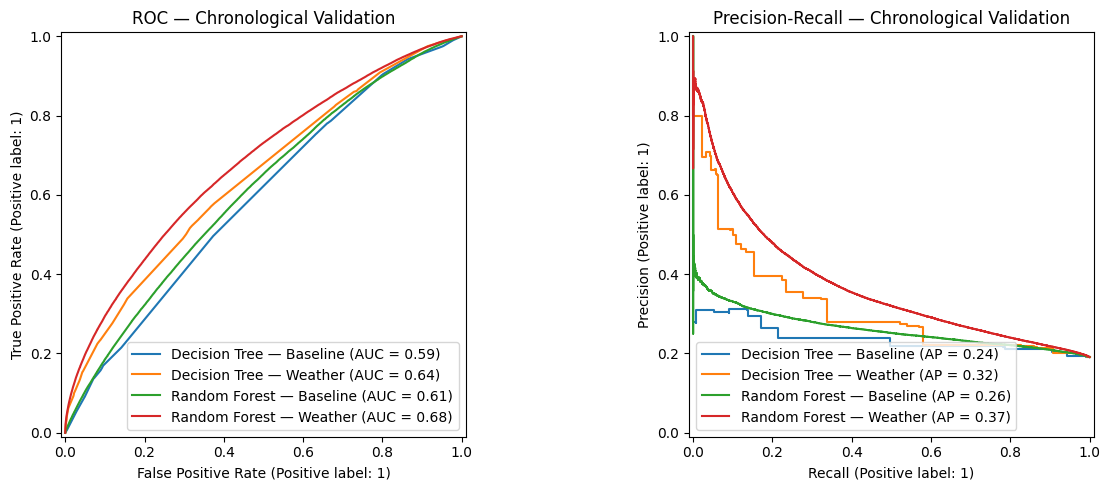

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, model in models.items():

    prob = model.predict_proba(
        val_df[feature_sets[name]]
    )[:, 1]

    RocCurveDisplay.from_predictions(
        val_df["is_delayed"],
        prob,
        name=name,
        ax=axes[0]
    )

    PrecisionRecallDisplay.from_predictions(
        val_df["is_delayed"],
        prob,
        name=name,
        ax=axes[1]
    )

axes[0].set_title("ROC — Chronological Validation")
axes[1].set_title("Precision-Recall — Chronological Validation")

plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

forest = models["Random Forest — Weather"]

X_val = val_df[weather_model_features]
y_val = val_df["is_delayed"]

val_prob = forest.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in np.arange(0.05, 0.51, 0.01):

    pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

best_threshold = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

display(
    threshold_df.sort_values("F1", ascending=False).head(10)
)

print("Best validation threshold:", best_threshold["Threshold"])
print("Best validation F1:", best_threshold["F1"])

,Threshold,Accuracy,Precision,Recall,F1
17,0.22,0.660174,0.297944,0.574914,0.392485
18,0.23,0.685363,0.310617,0.531293,0.392034
16,0.21,0.630004,0.284729,0.620187,0.390280
19,0.24,0.706959,0.323301,0.489210,0.389317
15,0.20,0.595274,0.271961,0.667666,0.386492
20,0.25,0.725557,0.335993,0.447986,0.383991
14,0.19,0.555450,0.259735,0.717943,0.381465
21,0.26,0.742388,0.350526,0.409444,0.377701
13,0.18,0.509042,0.247344,0.769138,0.374314
22,0.27,0.757232,0.366558,0.372831,0.369668


Best validation threshold: 0.22
Best validation F1: 0.3924854255455621


In [28]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    forest,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=5
)

importance_df = pd.DataFrame({
    "Feature": weather_model_features,
    "AP Decrease": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("AP Decrease", ascending=False)

display(importance_df)

,Feature,AP Decrease,Std
11,visibility_km,0.041273,0.000289
9,temperature_c,0.037951,0.000177
12,precipitation_mm,0.030494,0.000300
10,dew_point_depression,0.022702,0.000381
1,crs_dep_time_minutes,0.013226,0.000044
5,year,0.013077,0.000391
15,ceiling_height_m,0.012764,0.000058
4,month,0.010380,0.000129
3,scheduled_arrival_minutes,0.009513,0.000078
7,airline,0.003765,0.000034


Random Forest + Weather — Test Results
              precision    recall  f1-score   support

 Not Delayed       0.84      0.64      0.73    588828
     Delayed       0.36      0.62      0.45    188347

    accuracy                           0.63    777175
   macro avg       0.60      0.63      0.59    777175
weighted avg       0.72      0.63      0.66    777175

ROC-AUC: 0.6789332662265523
Average Precision: 0.4167177029979973


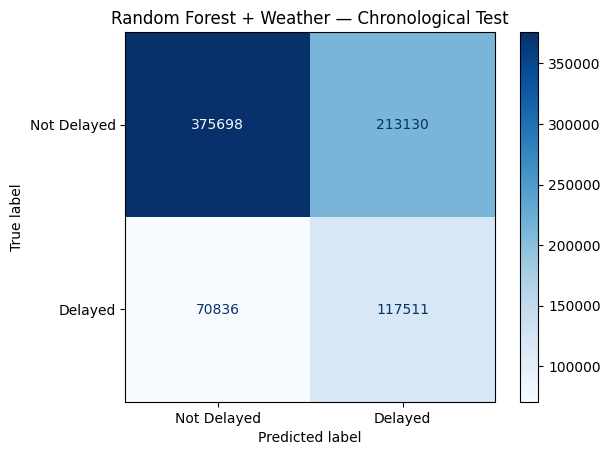

In [29]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score
)
import matplotlib.pyplot as plt

forest = models["Random Forest — Weather"]

threshold = 0.22

# Predict on the chronological test set
test_prob = forest.predict_proba(
    test_df[weather_model_features]
)[:, 1]

test_pred = (test_prob >= threshold).astype(int)

print("Random Forest + Weather — Test Results")
print(classification_report(
    test_df["is_delayed"],
    test_pred,
    target_names=["Not Delayed", "Delayed"],
    zero_division=0
))

print(
    "ROC-AUC:",
    roc_auc_score(test_df["is_delayed"], test_prob)
)

print(
    "Average Precision:",
    average_precision_score(test_df["is_delayed"], test_prob)
)

ConfusionMatrixDisplay.from_predictions(
    test_df["is_delayed"],
    test_pred,
    display_labels=["Not Delayed", "Delayed"],
    cmap="Blues"
)

plt.title("Random Forest + Weather — Chronological Test")
plt.show()

In [30]:
from sklearn.metrics import roc_auc_score, average_precision_score

baseline_prob = models["Random Forest — Baseline"].predict_proba(
    test_df[baseline_features]
)[:, 1]

weather_prob = models["Random Forest — Weather"].predict_proba(
    test_df[weather_model_features]
)[:, 1]

comparison = pd.DataFrame({
    "Model": ["Flight Only", "Flight + Weather"],
    "ROC-AUC": [
        roc_auc_score(test_df["is_delayed"], baseline_prob),
        roc_auc_score(test_df["is_delayed"], weather_prob)
    ],
    "Average Precision": [
        average_precision_score(test_df["is_delayed"], baseline_prob),
        average_precision_score(test_df["is_delayed"], weather_prob)
    ]
})

display(comparison.round(4))

,Model,ROC-AUC,Average Precision
0,Flight Only,0.6299,0.3450
1,Flight + Weather,0.6789,0.4167


In [31]:
print("Training flights:", len(train_df_small))
print("Start:", train_df_small["scheduled_departure_utc"].min())
print("End:", train_df_small["scheduled_departure_utc"].max())

Training flights: 250000
Start: 2016-08-07 23:55:00+00:00
End: 2020-08-07 23:50:00+00:00


In [32]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Existing feature sets
# baseline_features
# weather_model_features
# numerical_features
# weather_features
# categorical_features

def create_linear_preprocessor(use_weather=False):

    numeric = numerical_features.copy()

    if use_weather:
        numeric += weather_features

    return ColumnTransformer([
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(
                    strategy="median",
                    add_indicator=True
                )),
                ("scaler", StandardScaler())
            ]),
            numeric
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ])


linear_models = {
    "Multiple OLS — Flight Only": Pipeline([
        ("features", create_linear_preprocessor(False)),
        ("model", LinearRegression())
    ]),

    "Multiple OLS — Flight + Weather": Pipeline([
        ("features", create_linear_preprocessor(True)),
        ("model", LinearRegression())
    ])
}

linear_feature_sets = {
    "Multiple OLS — Flight Only": baseline_features,
    "Multiple OLS — Flight + Weather": weather_model_features
}

# Fit using our reduced chronological training sample
for name, model in linear_models.items():

    features = linear_feature_sets[name]

    model.fit(
        train_df_small[features],
        train_df_small["arrival_delay"]
    )

    print("Trained:", name)


Trained: Multiple OLS — Flight Only
Trained: Multiple OLS — Flight + Weather


In [33]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

results = []

for dataset_name, frame in [
    ("Validation", val_df),
    ("Test", test_df)
]:
    y_true = frame["arrival_delay"]

    for name, model in linear_models.items():

        features = linear_feature_sets[name]
        y_pred = model.predict(frame[features])

        results.append({
            "Dataset": dataset_name,
            "Model": name,
            "RMSE": np.sqrt(
                mean_squared_error(y_true, y_pred)
            ),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R²": r2_score(y_true, y_pred)
        })

linear_results = pd.DataFrame(results)

display(linear_results.round(4))

,Dataset,Model,RMSE,MAE,R²
0,Validation,Multiple OLS — Flight Only,50.1101,24.7334,0.0159
1,Validation,Multiple OLS — Flight + Weather,49.4421,23.9088,0.0419
2,Test,Multiple OLS — Flight Only,60.5754,27.9445,0.0148
3,Test,Multiple OLS — Flight + Weather,60.0047,27.3369,0.0332


In [34]:
from sklearn.dummy import DummyRegressor

mean_model = DummyRegressor(strategy="mean")

mean_model.fit(
    train_df_small[baseline_features],
    train_df_small["arrival_delay"]
)

baseline_results = []

for name, frame in [
    ("Validation", val_df),
    ("Test", test_df)
]:
    y_true = frame["arrival_delay"]

    y_pred = mean_model.predict(
        frame[baseline_features]
    )

    baseline_results.append({
        "Dataset": name,
        "Model": "Mean Baseline",
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred)
    })

all_linear_results = pd.concat([
    pd.DataFrame(baseline_results),
    linear_results
], ignore_index=True)

display(
    all_linear_results
    .sort_values(["Dataset", "RMSE"])
    .round(4)
)

,Dataset,Model,RMSE,MAE,R²
5,Test,Multiple OLS — Flight + Weather,60.0047,27.3369,0.0332
4,Test,Multiple OLS — Flight Only,60.5754,27.9445,0.0148
1,Test,Mean Baseline,61.0686,29.7279,-0.0014
3,Validation,Multiple OLS — Flight + Weather,49.4421,23.9088,0.0419
2,Validation,Multiple OLS — Flight Only,50.1101,24.7334,0.0159
0,Validation,Mean Baseline,50.6920,26.8220,-0.0071


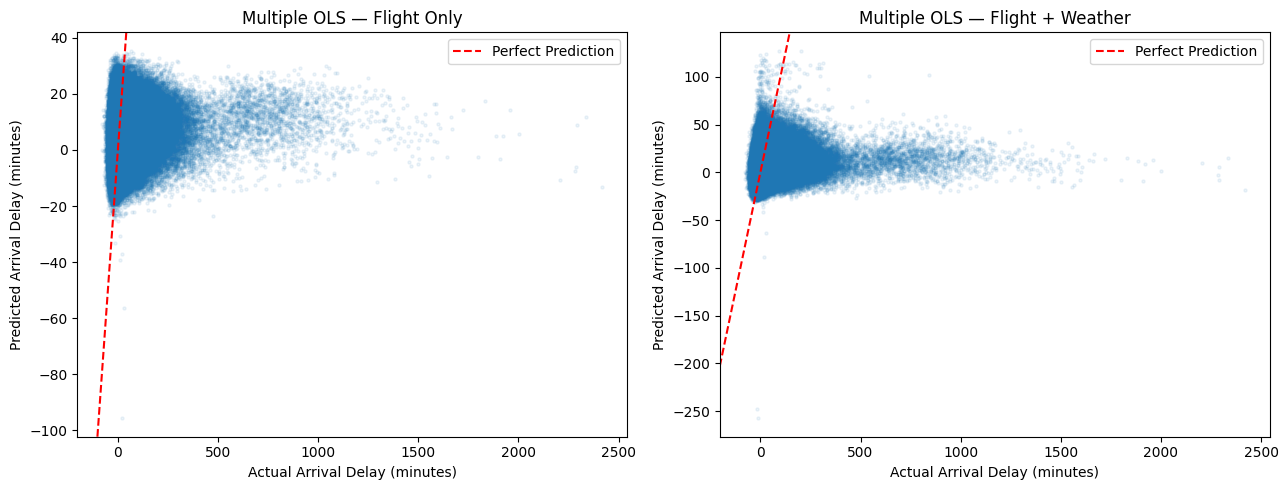

In [35]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, model) in zip(axes, linear_models.items()):

    predictions = model.predict(
        test_df[linear_feature_sets[name]]
    )

    ax.scatter(
        test_df["arrival_delay"],
        predictions,
        alpha=0.08,
        s=5
    )

    ax.axline(
        (0, 0),
        slope=1,
        color="red",
        linestyle="--",
        label="Perfect Prediction"
    )

    ax.set(
        title=name,
        xlabel="Actual Arrival Delay (minutes)",
        ylabel="Predicted Arrival Delay (minutes)"
    )

    ax.legend()

plt.tight_layout()
plt.show()

In [36]:
weather_predictions = linear_models[
    "Multiple OLS — Flight + Weather"
].predict(test_df[weather_model_features])

diagnostics = test_df[
    weather_model_features + ["arrival_delay"]
].copy()

diagnostics["predicted_delay"] = weather_predictions

display(
    diagnostics.nsmallest(
        15,
        "predicted_delay"
    )
)

,distance,crs_dep_time_minutes,scheduled_elapsed_time,scheduled_arrival_minutes,month,year,dayofweek,airline,dest_airport_group,temperature_c,dew_point_depression,visibility_km,precipitation_mm,wind_speed_m_s,wind_gust_m_s,ceiling_height_m,arrival_delay,predicted_delay
4691730,717.0,533,144.0,737,9,2024,5,YX,Other,21.1,4.4,177.028,0.0,2.6,NaN,9144.0,-13.0,-257.396640
4691731,802.0,534,149.0,683,9,2024,5,AA,DFW,21.1,4.4,177.028,0.0,2.6,NaN,9144.0,-17.0,-247.542771
4600785,157.0,639,491.0,1190,5,2024,2,OO,Other,21.7,5.0,14.484,0.0,2.6,NaN,7620.0,19.0,-88.239972
4999757,174.0,1010,346.0,1356,9,2025,4,OO,Other,30.6,18.9,16.093,NaN,2.1,NaN,NaN,30.0,-63.596223
4606331,84.0,860,260.0,1180,5,2024,2,OO,Other,21.7,10.6,16.000,NaN,3.6,NaN,NaN,11.0,-40.982193
4787512,258.0,595,248.0,843,1,2025,5,OO,Other,0.6,4.5,16.093,0.0,6.7,NaN,22000.0,13.0,-36.732033
4415796,2846.0,55,406.0,281,9,2023,6,AS,Other,22.2,7.2,16.093,0.0,3.1,NaN,22000.0,10.0,-33.370768
4379712,173.0,544,246.0,790,7,2023,6,OO,Other,21.7,1.1,16.093,0.0,2.6,NaN,22000.0,20.0,-32.537117
4471745,1739.0,380,276.0,536,11,2023,6,AS,Other,0.0,5.6,16.093,0.0,3.1,NaN,22000.0,-34.0,-31.213401
4476128,1739.0,380,276.0,536,11,2023,6,AS,Other,-2.2,7.8,16.093,0.0,0.0,NaN,701.0,-29.0,-30.781423


In [37]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

results_30 = []

for dataset_name, frame in [
    ("Validation", val_df),
    ("Test", test_df)
]:
    # Select flights with actual arrival delays between -30 and +30
    subset = frame[frame["arrival_delay"].between(-30, 30)]

    y_true = subset["arrival_delay"]

    for name, model in linear_models.items():

        features = linear_feature_sets[name]
        y_pred = model.predict(subset[features])

        results_30.append({
            "Dataset": dataset_name,
            "Model": name,
            "Flights": len(subset),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R²": r2_score(y_true, y_pred)
        })

results_30 = pd.DataFrame(results_30)

display(results_30.round(4))

,Dataset,Model,Flights,RMSE,MAE,R²
0,Validation,Multiple OLS — Flight Only,528399,18.5729,15.4968,-0.9303
1,Validation,Multiple OLS — Flight + Weather,528399,18.6963,15.1227,-0.9560
2,Test,Multiple OLS — Flight Only,629867,17.8370,14.8909,-0.6933
3,Test,Multiple OLS — Flight + Weather,629867,18.1808,14.6988,-0.7592
